In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats



In [3]:
df = pd.read_excel('/content/Pharmacy_data.xlsx')
df.head()

,SalesID,DateKey,PharmacyID,ProductID,UnitsSold,RevenueEUR,CostEUR,MarginEUR,PromoFlag
0,S0000001,20240101,PH0002,PR0099,5,128.08,87.55,40.53,No
1,S0000002,20240101,PH0004,PR0156,4,51.89,34.32,17.57,No
2,S0000003,20240101,PH0007,PR0004,20,317.73,199.53,118.20,No
3,S0000004,20240101,PH0009,PR0075,6,90.34,67.49,22.85,No
4,S0000005,20240101,PH0010,PR0154,2,160.21,124.99,35.22,Yes


In [4]:
df.tail()

,SalesID,DateKey,PharmacyID,ProductID,UnitsSold,RevenueEUR,CostEUR,MarginEUR,PromoFlag
62134,S0062135,20251231,PH0117,PR0101,2,159.56,118.31,41.25,Yes
62135,S0062136,20251231,PH0118,PR0125,5,136.15,92.63,43.52,No
62136,S0062137,20251231,PH0120,PR0183,4,43.51,30.22,13.29,No
62137,S0062138,20251231,PH0120,PR0151,11,129.27,83.37,45.90,No
62138,S0062139,20251231,PH0120,PR0145,3,227.54,177.03,50.51,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62139 entries, 0 to 62138
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SalesID     62139 non-null  object 
 1   DateKey     62139 non-null  int64  
 2   PharmacyID  62139 non-null  object 
 3   ProductID   62139 non-null  object 
 4   UnitsSold   62139 non-null  int64  
 5   RevenueEUR  62139 non-null  float64
 6   CostEUR     62139 non-null  float64
 7   MarginEUR   62139 non-null  float64
 8   PromoFlag   62139 non-null  object 
dtypes: float64(3), int64(2), object(4)
memory usage: 4.3+ MB


In [19]:
df.shape

(62139, 9)

In [20]:
df['CostEUR'].nunique()

22745

In [21]:
df['CostEUR'].unique()

array([ 87.55,  34.32, 199.53, ..., 190.86, 232.73, 149.72],
      shape=(22745,))

In [22]:
df['MarginEUR'].nunique()

12262

In [23]:
df['MarginEUR'].unique()

array([ 40.53,  17.57, 118.2 , ..., 177.56, 101.19, 115.63],
      shape=(12262,))

In [24]:
df['PromoFlag'].nunique()

2

In [25]:
df['PromoFlag'].unique()

array(['No', 'Yes'], dtype=object)

In [26]:
df['SalesID'].nunique()

62139

In [27]:
df['SalesID'].unique()

array(['S0000001', 'S0000002', 'S0000003', ..., 'S0062137', 'S0062138',
       'S0062139'], shape=(62139,), dtype=object)

In [28]:
df['DateKey'].nunique()

731

In [29]:
df['DateKey'].unique()

array([20240101, 20240102, 20240103, 20240104, 20240105, 20240106,
       20240107, 20240108, 20240109, 20240110, 20240111, 20240112,
       20240113, 20240114, 20240115, 20240116, 20240117, 20240118,
       20240119, 20240120, 20240121, 20240122, 20240123, 20240124,
       20240125, 20240126, 20240127, 20240128, 20240129, 20240130,
       20240131, 20240201, 20240202, 20240203, 20240204, 20240205,
       20240206, 20240207, 20240208, 20240209, 20240210, 20240211,
       20240212, 20240213, 20240214, 20240215, 20240216, 20240217,
       20240218, 20240219, 20240220, 20240221, 20240222, 20240223,
       20240224, 20240225, 20240226, 20240227, 20240228, 20240229,
       20240301, 20240302, 20240303, 20240304, 20240305, 20240306,
       20240307, 20240308, 20240309, 20240310, 20240311, 20240312,
       20240313, 20240314, 20240315, 20240316, 20240317, 20240318,
       20240319, 20240320, 20240321, 20240322, 20240323, 20240324,
       20240325, 20240326, 20240327, 20240328, 20240329, 20240

In [30]:
df['PharmacyID'].nunique()

120

In [31]:
df['PharmacyID'].unique()

array(['PH0002', 'PH0004', 'PH0007', 'PH0009', 'PH0010', 'PH0012',
       'PH0015', 'PH0018', 'PH0024', 'PH0025', 'PH0026', 'PH0027',
       'PH0028', 'PH0029', 'PH0031', 'PH0032', 'PH0033', 'PH0035',
       'PH0039', 'PH0041', 'PH0045', 'PH0046', 'PH0047', 'PH0051',
       'PH0054', 'PH0056', 'PH0057', 'PH0060', 'PH0063', 'PH0064',
       'PH0066', 'PH0068', 'PH0070', 'PH0071', 'PH0075', 'PH0077',
       'PH0078', 'PH0079', 'PH0081', 'PH0086', 'PH0088', 'PH0089',
       'PH0093', 'PH0095', 'PH0096', 'PH0097', 'PH0099', 'PH0101',
       'PH0104', 'PH0105', 'PH0106', 'PH0108', 'PH0109', 'PH0111',
       'PH0112', 'PH0114', 'PH0116', 'PH0117', 'PH0118', 'PH0120',
       'PH0008', 'PH0016', 'PH0021', 'PH0034', 'PH0037', 'PH0044',
       'PH0048', 'PH0049', 'PH0053', 'PH0059', 'PH0067', 'PH0072',
       'PH0073', 'PH0083', 'PH0091', 'PH0094', 'PH0098', 'PH0107',
       'PH0110', 'PH0113', 'PH0119', 'PH0005', 'PH0017', 'PH0020',
       'PH0022', 'PH0023', 'PH0036', 'PH0058', 'PH0062', 'PH00

In [32]:
df['ProductID'].nunique()

220

In [33]:
df['ProductID'].unique()

array(['PR0099', 'PR0156', 'PR0004', 'PR0075', 'PR0154', 'PR0132',
       'PR0153', 'PR0047', 'PR0038', 'PR0064', 'PR0119', 'PR0149',
       'PR0143', 'PR0179', 'PR0151', 'PR0053', 'PR0050', 'PR0218',
       'PR0022', 'PR0135', 'PR0052', 'PR0137', 'PR0012', 'PR0204',
       'PR0115', 'PR0166', 'PR0103', 'PR0193', 'PR0049', 'PR0097',
       'PR0040', 'PR0087', 'PR0002', 'PR0174', 'PR0102', 'PR0162',
       'PR0161', 'PR0215', 'PR0091', 'PR0009', 'PR0029', 'PR0110',
       'PR0068', 'PR0113', 'PR0079', 'PR0175', 'PR0200', 'PR0116',
       'PR0078', 'PR0163', 'PR0013', 'PR0083', 'PR0190', 'PR0158',
       'PR0041', 'PR0089', 'PR0138', 'PR0007', 'PR0203', 'PR0086',
       'PR0197', 'PR0196', 'PR0054', 'PR0034', 'PR0157', 'PR0008',
       'PR0060', 'PR0076', 'PR0107', 'PR0033', 'PR0136', 'PR0213',
       'PR0164', 'PR0096', 'PR0120', 'PR0051', 'PR0211', 'PR0170',
       'PR0095', 'PR0035', 'PR0117', 'PR0206', 'PR0165', 'PR0155',
       'PR0032', 'PR0073', 'PR0147', 'PR0045', 'PR0093', 'PR01

In [34]:
df['UnitsSold'].nunique()

25

In [35]:
df['UnitsSold'].unique()

array([ 5,  4, 20,  6,  2,  8, 11, 13,  3, 10, 12,  1,  9,  7, 16, 17, 18,
       15, 22, 14, 19, 21, 25, 23, 24])

In [36]:
df['RevenueEUR'].nunique()

18299

In [37]:
df['RevenueEUR'].unique()

array([128.08,  51.89, 317.73, ..., 201.43,  71.54, 175.68],
      shape=(18299,))

In [38]:
df.isnull().sum()

,0
SalesID,0
DateKey,0
PharmacyID,0
ProductID,0
UnitsSold,0
RevenueEUR,0
CostEUR,0
MarginEUR,0
PromoFlag,0


In [39]:
df.head()

,SalesID,DateKey,PharmacyID,ProductID,UnitsSold,RevenueEUR,CostEUR,MarginEUR,PromoFlag
0,S0000001,20240101,PH0002,PR0099,5,128.08,87.55,40.53,No
1,S0000002,20240101,PH0004,PR0156,4,51.89,34.32,17.57,No
2,S0000003,20240101,PH0007,PR0004,20,317.73,199.53,118.20,No
3,S0000004,20240101,PH0009,PR0075,6,90.34,67.49,22.85,No
4,S0000005,20240101,PH0010,PR0154,2,160.21,124.99,35.22,Yes


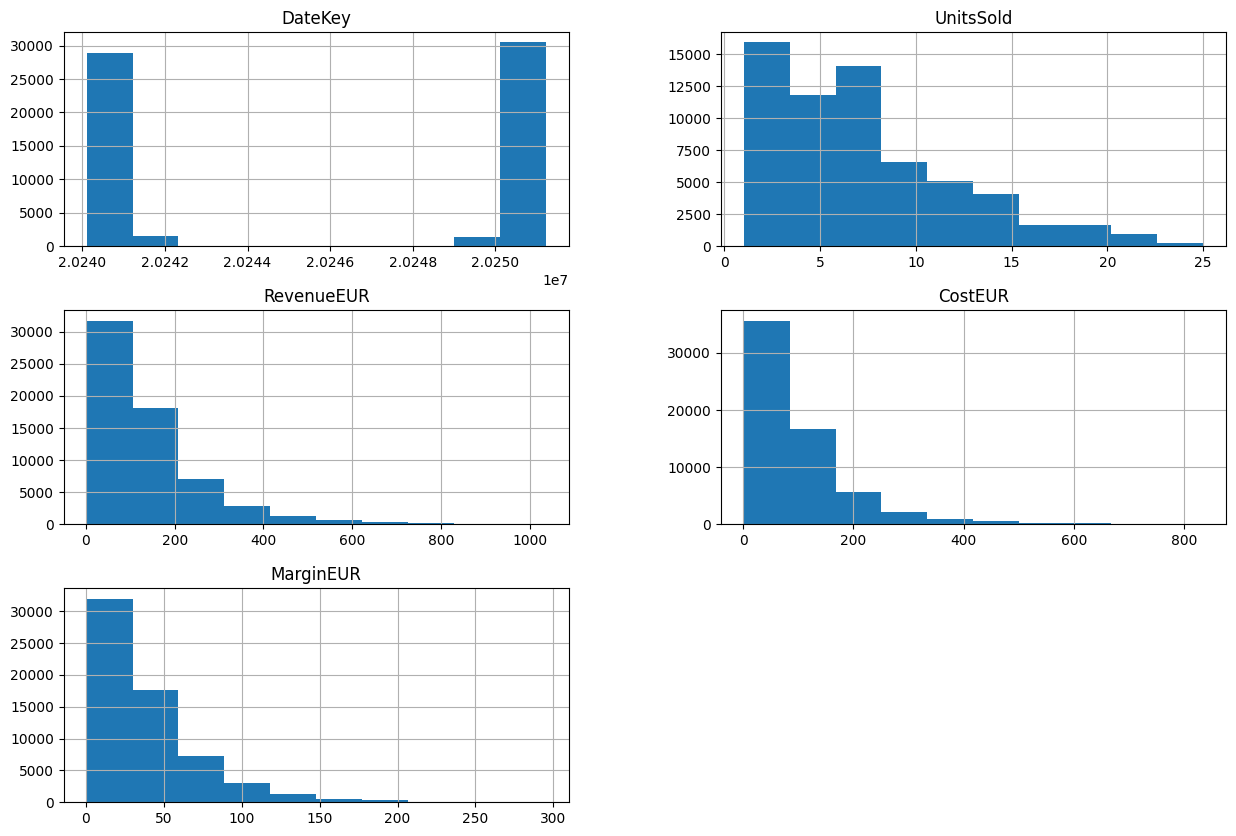

In [40]:
df.hist(figsize=(15,10))
plt.show()

In [41]:
df.sample(3)

,SalesID,DateKey,PharmacyID,ProductID,UnitsSold,RevenueEUR,CostEUR,MarginEUR,PromoFlag
4357,S0004358,20240222,PH0052,PR0200,6,46.97,32.72,14.25,No
20122,S0020123,20240830,PH0021,PR0153,6,94.15,55.02,39.13,No
8626,S0008627,20240415,PH0033,PR0019,5,305.38,237.14,68.24,No


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62139 entries, 0 to 62138
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SalesID     62139 non-null  object 
 1   DateKey     62139 non-null  int64  
 2   PharmacyID  62139 non-null  object 
 3   ProductID   62139 non-null  object 
 4   UnitsSold   62139 non-null  int64  
 5   RevenueEUR  62139 non-null  float64
 6   CostEUR     62139 non-null  float64
 7   MarginEUR   62139 non-null  float64
 8   PromoFlag   62139 non-null  object 
dtypes: float64(3), int64(2), object(4)
memory usage: 4.3+ MB


In [43]:
df.head()

,SalesID,DateKey,PharmacyID,ProductID,UnitsSold,RevenueEUR,CostEUR,MarginEUR,PromoFlag
0,S0000001,20240101,PH0002,PR0099,5,128.08,87.55,40.53,No
1,S0000002,20240101,PH0004,PR0156,4,51.89,34.32,17.57,No
2,S0000003,20240101,PH0007,PR0004,20,317.73,199.53,118.20,No
3,S0000004,20240101,PH0009,PR0075,6,90.34,67.49,22.85,No
4,S0000005,20240101,PH0010,PR0154,2,160.21,124.99,35.22,Yes


In [44]:
df.describe()

,DateKey,UnitsSold,RevenueEUR,CostEUR,MarginEUR
count,6.213900e+04,62139.000000,62139.000000,62139.000000,62139.000000
mean,2.024579e+07,7.174126,138.946190,99.982881,38.963309
std,5.014700e+03,4.873395,124.574712,93.611370,33.972445
min,2.024010e+07,1.000000,1.610000,1.100000,0.440000
25%,2.024071e+07,3.000000,55.250000,39.330000,15.140000
50%,2.025011e+07,6.000000,102.750000,72.220000,28.990000
75%,2.025071e+07,10.000000,181.350000,128.680000,51.990000
max,2.025123e+07,25.000000,1036.280000,834.420000,295.310000


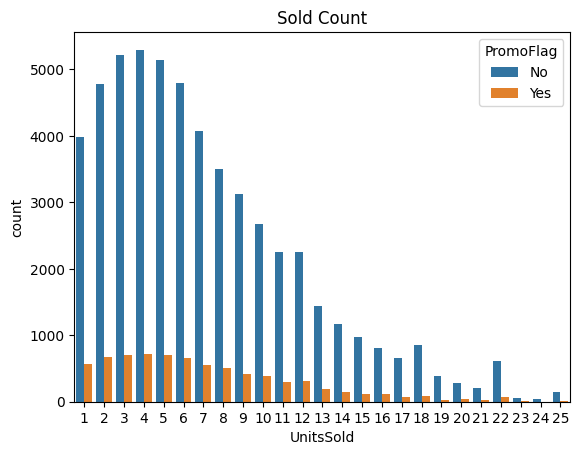

In [49]:
sns.countplot(x='UnitsSold' , hue='PromoFlag',data=df)
plt.title('Sold Count')
plt.show()

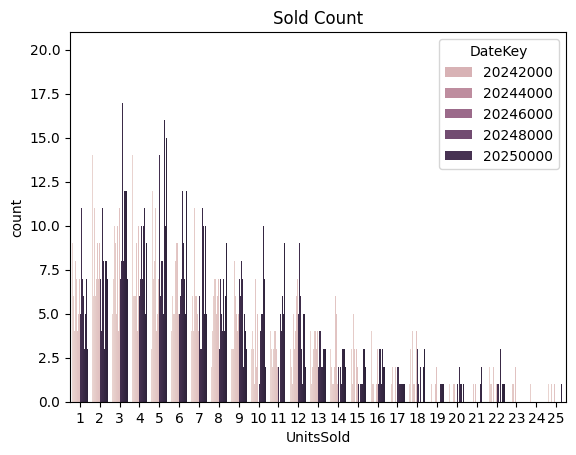

In [52]:
sns.countplot(x='UnitsSold' , hue='DateKey',data=df)
plt.title('Sold Count')
plt.show()

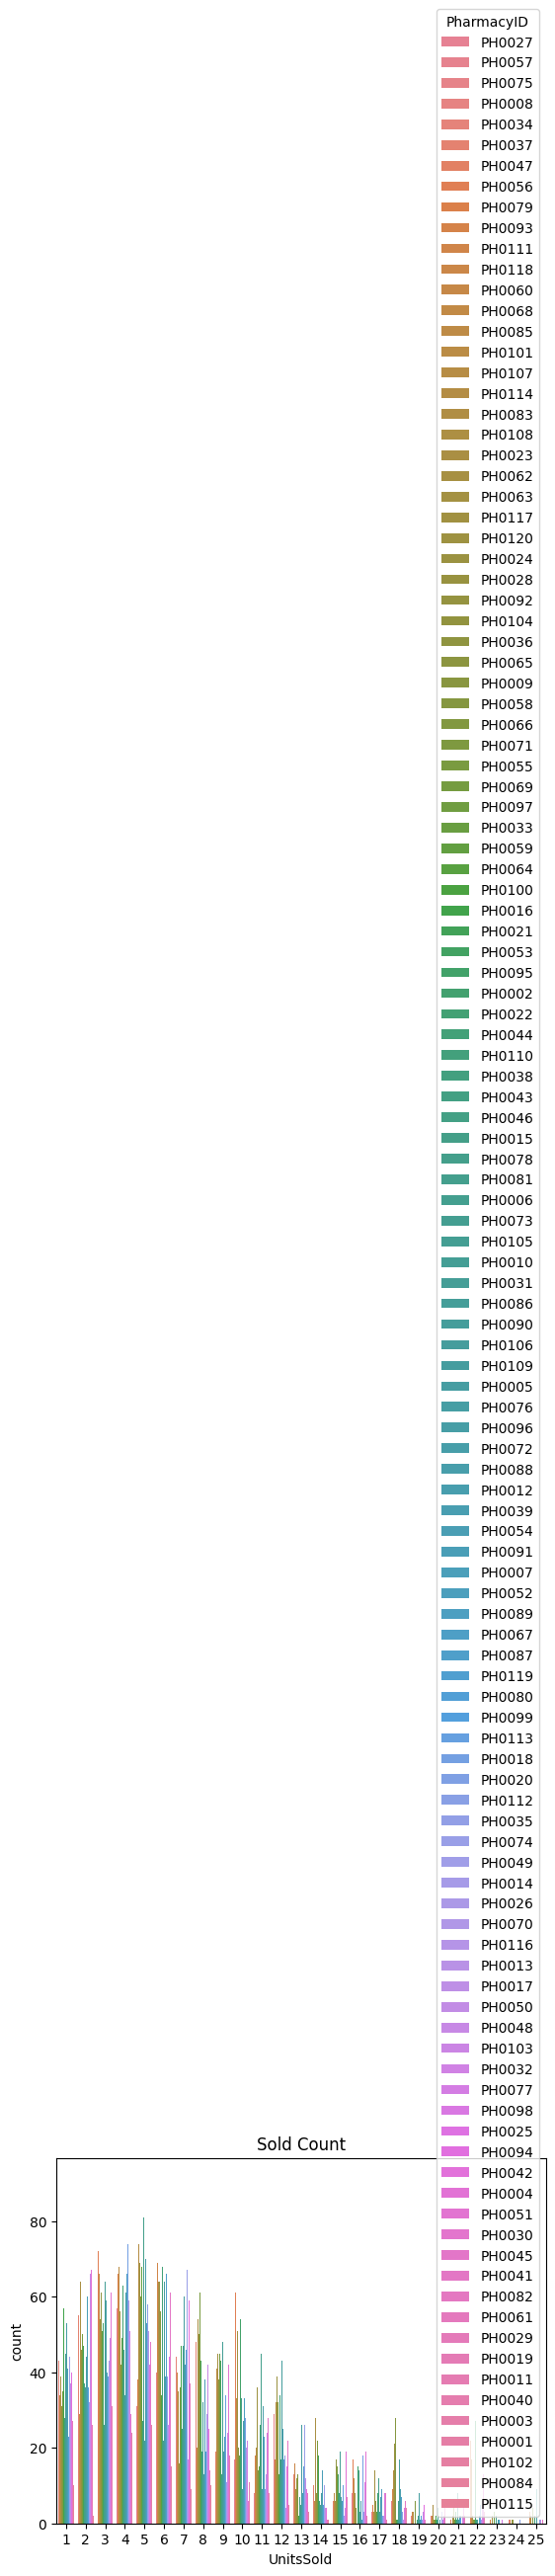

In [53]:
sns.countplot(x='UnitsSold' , hue='PharmacyID',data=df)
plt.title('Sold Count')
plt.show()

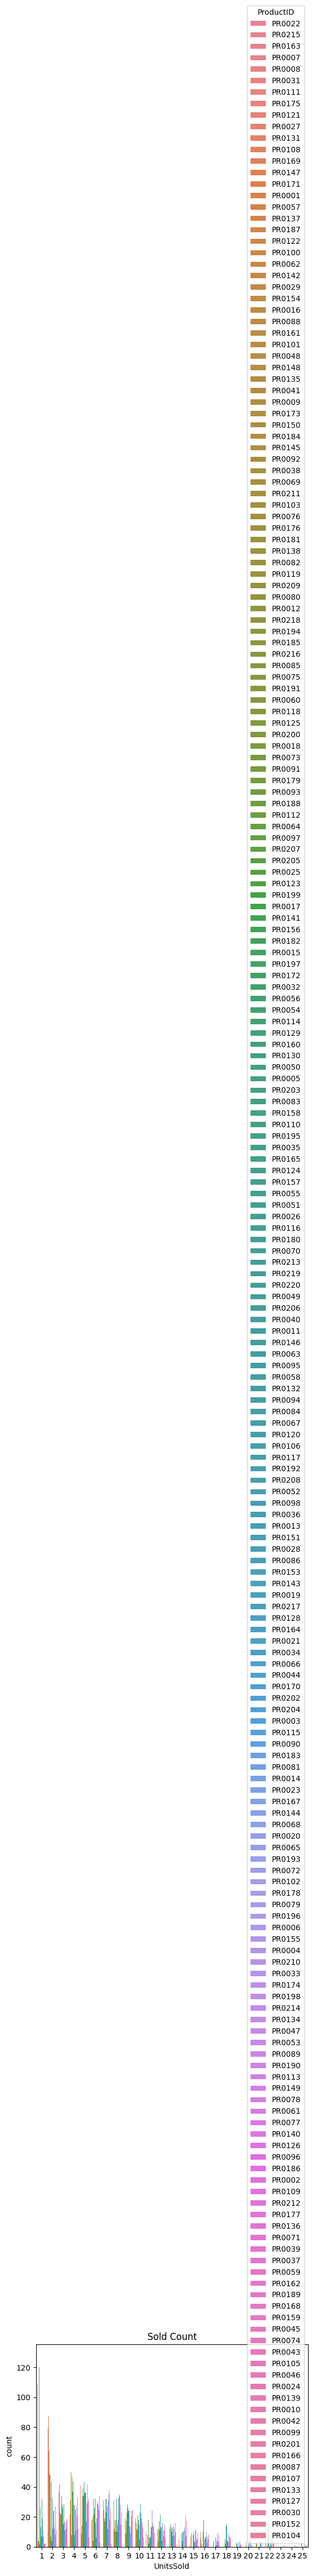

In [54]:
sns.countplot(x='UnitsSold' , hue='ProductID',data=df)
plt.title('Sold Count')
plt.show()